In [4]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
%pip install -q tensorflow-datasets fastapi uvicorn python-multipart pillow

In [6]:
import os
import io
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print("All libraries imported successfully!")
print("GPU:", tf.config.list_physical_devices("GPU"))

All libraries imported successfully!
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
%pip install -q importlib_resources

In [8]:
import tensorflow_datasets as tfds

(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names

print("Dataset downloaded and loaded successfully!")
print("Total images:", info.splits["train"].num_examples)
print("Flower classes:", class_names)
print("Training images:", len(list(train_raw)))
print("Validation images:", len(list(val_raw)))
print("Test images:", len(list(test_raw)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.GW94QF_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Dataset downloaded and loaded successfully!
Total images: 3670
Flower classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Training images: 2569
Validation images: 551
Test images: 550


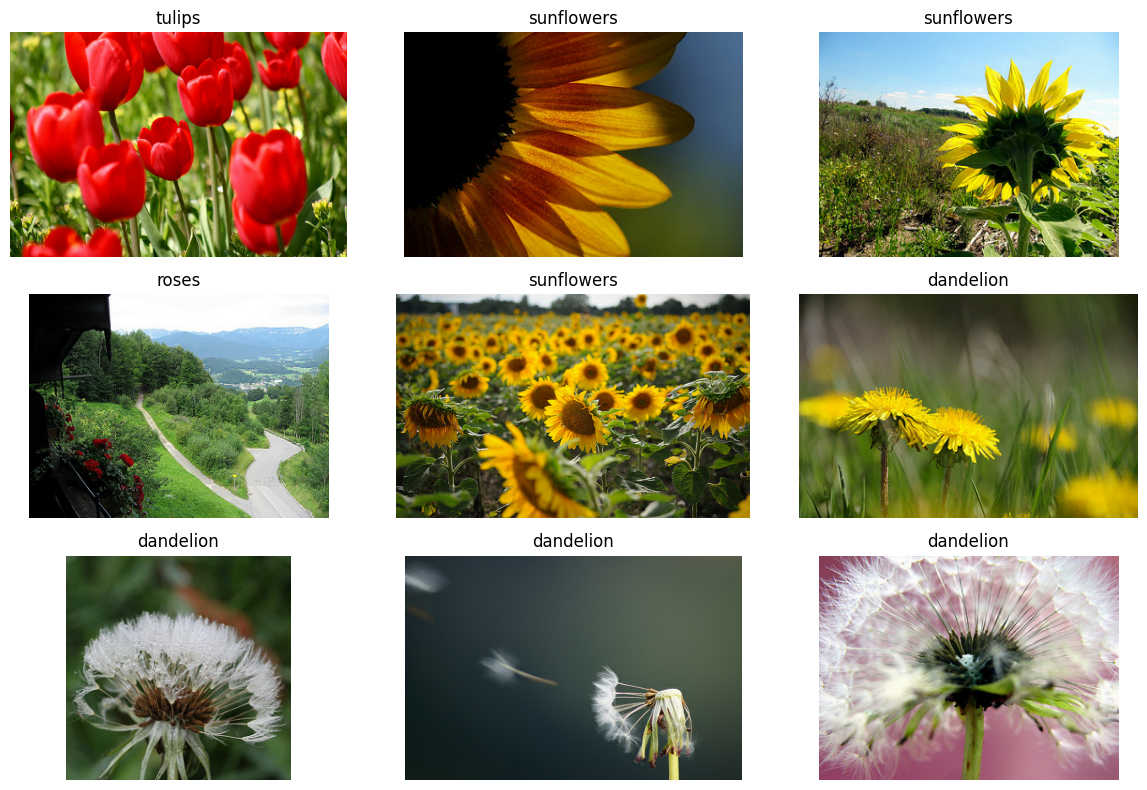

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, (image, label) in enumerate(train_raw.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[int(label.numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
IMG_SIZE = 224
BATCH_SIZE = 32

def prepare_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

train_ds = (
    train_raw
    .map(prepare_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_raw
    .map(prepare_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_raw
    .map(prepare_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Images resized successfully!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", len(class_names))

Images resized successfully!
Image size: 224 x 224
Batch size: 32
Number of classes: 5


In [11]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep the pretrained layers frozen initially
base_model.trainable = False

print("ResNet50 loaded successfully!")
print("Pretrained layers are frozen.")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
ResNet50 loaded successfully!
Pretrained layers are frozen.


In [12]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,629 (90.98 MB)

 Trainable params: 262,917 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [13]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 47s 285ms/step - accuracy: 0.7785 - loss: 0.6384 - val_accuracy: 0.8929 - val_loss: 0.3485
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.8968 - loss: 0.3020 - val_accuracy: 0.9074 - val_loss: 0.2686
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - accuracy: 0.9218 - loss: 0.2271 - val_accuracy: 0.9238 - val_loss: 0.2473
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 112ms/step - accuracy: 0.9420 - loss: 0.1674 - val_accuracy: 0.9183 - val_loss: 0.2434
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - accuracy: 0.9560 - loss: 0.1304 - val_accuracy: 0.9165 - val_loss: 0.2696
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - accuracy: 0.9630 - loss: 0.1047 - val_accuracy: 0.9129 - val_loss: 0.2587
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 116ms/step - accuracy: 0.9638 - loss: 0.1023 - val_accuracy: 0.9147 - val_loss: 0.2584
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 119ms/step - accuracy: 0.9716 - loss: 0.0845 - val_accur

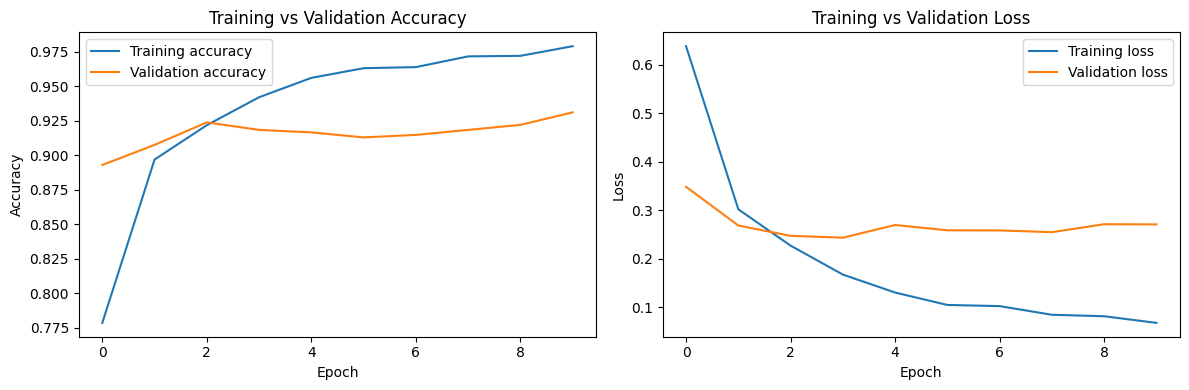

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 289ms/step - accuracy: 0.9127 - loss: 0.2686
Test accuracy: 91.27%
Test loss: 0.2686


In [16]:
model.save("/content/flower_resnet50.keras")

print("Model saved successfully!")

Model saved successfully!


In [17]:
import os
print(os.path.exists("/content/flower_resnet50.keras"))

True


In [18]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

model = tf.keras.models.load_model(
    "/content/flower_resnet50.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)


In [19]:
%%writefile app.py
import io
import numpy as np
import tensorflow as tf
from PIL import Image, UnidentifiedImageError
from fastapi import FastAPI, File, HTTPException, UploadFile
from tensorflow.keras.applications.resnet50 import preprocess_input

app = FastAPI(
    title="Flower Classification AI",
    description="Classifies images into five flower categories",
    version="1.0"
)

model = tf.keras.models.load_model(
    "/content/flower_resnet50.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

class_names = [
    "dandelion",
    "daisy",
    "tulips",
    "sunflowers",
    "roses"
]

@app.get("/")
def home():
    return {"message": "Flower Classification AI API is running"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    image_data = await file.read()

    try:
        image = Image.open(io.BytesIO(image_data)).convert("RGB")
    except (UnidentifiedImageError, OSError):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image."
        )

    image = image.resize((224, 224))
    image_array = np.array(image, dtype=np.float32)
    image_batch = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_batch, verbose=0)[0]
    top_indices = np.argsort(predictions)[::-1][:3]

    return {
        "prediction": class_names[int(top_indices[0])],
        "confidence": round(
            float(predictions[top_indices[0]]) * 100, 2
        ),
        "top_3": [
            {
                "flower": class_names[int(i)],
                "confidence": round(float(predictions[i]) * 100, 2)
            }
            for i in top_indices
        ]
    }

Writing app.py


In [20]:
!pip install fastapi uvicorn python-multipart

In [ ]:
!uvicorn app:app --host 0.0.0.0 --port 8000

W0000 00:00:1791818105.099636    3773 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [3773]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


In [ ]:
import subprocess
import time

# Start uvicorn in the background and redirect output to a log file
with open("uvicorn.log", "w") as log_file:
    process = subprocess.Popen(
        ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"],
        stdout=log_file,
        stderr=log_file
    )

# Give the server 3 seconds to spin up
time.sleep(3)
print("Uvicorn started in the background! Logs are written to uvicorn.log")

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8000)")
print(url.rstrip("/") + "/docs")